In [1]:
import sys
import os
sys.path.append(os.path.abspath('../../'))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from functions.preproc import *
from functions.ucphm import *
from functions.new_variables import *
from functions.ensembles import *
from scipy.stats import skew, shapiro

In [2]:
dataset = pd.read_excel('../../BreastCareCond.xlsx')
data_code = pd.read_excel('../../Codificação variaveis.xlsx')

Using the variables she used

This also as the surgery data, the only data that appeared here were this three variables 'Type of 1st intervention', 'Axillary operation', 'SLN procedure'

In [3]:
#Defining the proposed has good treatment variables to use (the empty ones were removed)
relevant_variables = ['PERSON_ID', 'Regional LN recurrence', 'Date of 1st regional recurrence', 'EBC', 'Survival days']
numerical_variables = ['Age', 'Ki67 positive cells (%) at CB', 'N (Regional nodes affected)']
categorical_variables = ['Number identifying the lesion in the patient', 
                         'Side location of the lesion', 'Classification with respect to other lesions', 
                         'Source of referral', 'Type of invasion at CB', 'Istotype at CB', 
                         'Oestrogen receptor status at CB', 'Progesterone receptor status at CB', 
                         'Disease extent', 'Grade at CB', 'Her2 overexpression (with immunohystochemistry) at CB']
                         
# surgery_variables = ['Type of 1st intervention', 'Axillary operation', 'SLN procedure']                       

date_columns = ['Date of CB ', 'Date of 1st breast operation', 'Date of intervention on sentinel lymph node',
                'Date of intervention (axilla)']

In [4]:
dataset = date_of_diagnosis(dataset, date_columns)

relevant_dates = ['Date of diagnosis', 'Date of 1st regional recurrence']
dataset = remove_zeros_na(dataset, relevant_dates)
dataset = format_date(dataset, relevant_dates)

dataset = survival_days(dataset, ['Date of diagnosis'], ['Date of 1st regional recurrence'])
dataset = tte_negative_patients(dataset)
dataset = filter_EBC(dataset)
dataset.reset_index(drop=True, inplace=True)

In [5]:
cT (dataset)
clinical_staging (dataset)
new_variables = ['cT']
categorical_variables = categorical_variables + new_variables
dataset['cT'] = dataset['cT'].replace('TX', np.nan)

In [6]:
change_to_numeric(dataset, numerical_variables)
change_to_categorical(dataset, categorical_variables)

Done
Done


In [7]:
columns_to_map = {
    'Side location of the lesion': {'L': 0, 'R': 1},
    'Source of referral': {1: 0, 2: 1},
    'Type of invasion at CB': {1: 0, 2: 1},
    'Oestrogen receptor status at CB': {1: 0, 2: 1},
    'Progesterone receptor status at CB': {1: 0, 2: 1}
}

for column, mapping in columns_to_map.items():
    dataset[column] = dataset[column].map(mapping)

In [8]:
# Replace missing values in the specified columns
dataset['Side location of the lesion'] = dataset['Side location of the lesion'].fillna(dataset['Side location of the lesion'].mode(dropna=True).iloc[0])
dataset['Classification with respect to other lesions'] = dataset['Classification with respect to other lesions'].fillna(1)
dataset['Istotype at CB'] = dataset['Istotype at CB'].fillna(0)
dataset['Disease extent'] = dataset['Disease extent'].fillna(0)

dataset['N (Regional nodes affected)'] = dataset['N (Regional nodes affected)'].fillna(0)

In [9]:
cT = ['cT']
replace_missing_values(dataset, cT, 'unknown')

Done


In [10]:
handle_missing = ['Type of invasion at CB', 'Oestrogen receptor status at CB', 'Progesterone receptor status at CB',
                  'Grade at CB', 'Her2 overexpression (with immunohystochemistry) at CB']
dataset, new_columns = one_hot_encode_with_missing_indicator(dataset, handle_missing)
categorical_variables = [col for col in categorical_variables if col not in handle_missing]
categorical_variables.extend(new_columns)

In [11]:
test_normality(dataset, numerical_variables)

,Variable,Skewness,Shapiro p-value,Normality,Has Outliers
0,Age,0.242395,6.016021e-17,Probably not normal,False
1,Ki67 positive cells (%) at CB,0.990633,6.576869e-39,Probably not normal,True
2,N (Regional nodes affected),2.163681,4.549008e-68,Probably not normal,True


In [12]:
median = ['Ki67 positive cells (%) at CB']

In [13]:
median_imputer(dataset, numerical_variables)

'Done'

In [14]:
one_hot_variables = ['Number identifying the lesion in the patient', 'Classification with respect to other lesions', 'Istotype at CB', 'Disease extent', 'cT']
ohe_dataset, new_column_names = one_hot_encoding(dataset, one_hot_variables, drop_first='first')

In [15]:
categorical_variables = [col for col in categorical_variables if col not in one_hot_variables]
categorical_variables.extend(new_column_names.tolist())

selected_variables = relevant_variables + numerical_variables + categorical_variables

date_of_diagnosis = ['Date of diagnosis']
selected_variables = selected_variables + date_of_diagnosis

In [16]:
#removi a endocrine
treatment_variables = ['Radiotherapy (RT) performed', 'Conventional RT fraction', 'Total administered dose', 'Boost dose administered', 
                       'Radiotherapy on chest wall', 'Radiotherapy on supraclavicular area', 'Radiotherapy on internal mammary chain',
                         'State (if hormone therapy prescribed)', 'Treatment in association with chemotherapy', 
                        'Chemotherapy performed', 'Adjuvant chemotherapy', 'Adjuvant therapy with biological drugs', 'Endocrine therapy performed']
selected_variables_treat = selected_variables + treatment_variables

survival_dataset = ohe_dataset[selected_variables_treat].copy()

Now the treatment variables, just because it was already made

In [17]:
dataset = survival_dataset

In [18]:
numerical_data, categorical_data = type_separation(data_code, treatment_variables)
len(numerical_data), len(categorical_data)

(3, 10)

In [19]:
replace_missing_values(dataset, numerical_data, 0)

Done


In [20]:
dataset.drop(index=0, inplace=True)
dataset.reset_index(inplace=True, drop=True)
replace_missing_values(dataset, categorical_data, 0)

Done


In [21]:
#remoived the 'Endocrine therapy performed'
variable_two_to_zero = ['Adjuvant chemotherapy', 'Chemotherapy performed', 'Endocrine therapy performed']
def two_to_zero(dataset, variables):
    for variable in variables:
        dataset[variable] = dataset[variable].replace(2, 0)
    return 'Done'

two_to_zero(dataset, variable_two_to_zero)

bio_variable = 'Adjuvant therapy with biological drugs'
one_hot_dataset = encode_bio_therapy(dataset, bio_variable)

In [22]:
feature_columns = ['Adjuvant therapy with bio drugs', 'Trastuzumab or other drugs']
feature_columns = feature_columns + categorical_data + numerical_data
bio_variable = ['Adjuvant therapy with biological drugs']
treatment_variables = [col for col in feature_columns if col not in bio_variable]

In [23]:
to_remove = ['PERSON_ID', 'Regional LN recurrence', 'Date of 1st regional recurrence', 'EBC', 'Date of diagnosis', 'Survival days']
important_variables = ['PERSON_ID', 'Regional LN recurrence', 'Survival days']
diagnosis_variables = [col for col in selected_variables if col not in to_remove]
selected_columns = important_variables + treatment_variables + diagnosis_variables

In [24]:
survival_dataset = one_hot_dataset[selected_columns]

In [25]:
# Check if there are any NaN values in the dataset
contains_nan = survival_dataset.isnull().any().any()
print("Does survival_dataset contain NaN values?", contains_nan)

# Optionally, to see which columns contain NaN values
nan_columns = survival_dataset.columns[survival_dataset.isnull().any()].tolist()
print("Columns with NaN values:", nan_columns)

Does survival_dataset contain NaN values? False
Columns with NaN values: []


In [29]:
survival_dataset.to_csv("data_final.csv")

In [28]:
with open("diagnosis_final.txt", "w") as file:
    for item in diagnosis_variables:
        file.write(str(item) + "\n")
with open("treatment_final.txt", "w") as file:
    for item in treatment_variables:
        file.write(str(item) + "\n")

# Censoring analysis

Checking censoring patterns here, heavy censoring vs just class imbalance, worth separating those out.

In [3]:
import pandas as pd
survival_dataset = pd.read_csv("data_final.csv")

In [4]:
# Basic censoring statistics
total_patients = len(survival_dataset)
events = len(survival_dataset[survival_dataset['Regional LN recurrence'] == 1])
censored = len(survival_dataset[survival_dataset['Regional LN recurrence'] == 0])

print("=== CENSORING ANALYSIS ===")
print(f"Total patients: {total_patients}")
print(f"Events (Regional LN recurrence = 1): {events}")
print(f"Censored (Regional LN recurrence = 0): {censored}")
print(f"Event rate: {events/total_patients:.3f} ({events/total_patients*100:.1f}%)")
print(f"Censoring rate: {censored/total_patients:.3f} ({censored/total_patients*100:.1f}%)")
print()

# Heavy censoring is typically defined as >70-80% censoring rate
if censored/total_patients > 0.8:
    print("⚠️  HEAVILY CENSORED DATA (>80% censoring)")
elif censored/total_patients > 0.7:
    print("⚠️  MODERATELY CENSORED DATA (70-80% censoring)")
else:
    print("✅ REASONABLE CENSORING RATE (<70%)")

=== CENSORING ANALYSIS ===
Total patients: 3230
Events (Regional LN recurrence = 1): 36
Censored (Regional LN recurrence = 0): 3194
Event rate: 0.011 (1.1%)
Censoring rate: 0.989 (98.9%)

⚠️  HEAVILY CENSORED DATA (>80% censoring)


In [5]:
# Survival time statistics by censoring status
print("=== SURVIVAL TIME DISTRIBUTION ===")
print("\nFor patients with events (Regional LN recurrence = 1):")
event_times = survival_dataset[survival_dataset['Regional LN recurrence'] == 1]['Survival days']
if len(event_times) > 0:
    print(f"  Count: {len(event_times)}")
    print(f"  Mean survival time: {event_times.mean():.1f} days")
    print(f"  Median survival time: {event_times.median():.1f} days")
    print(f"  Min survival time: {event_times.min():.1f} days")
    print(f"  Max survival time: {event_times.max():.1f} days")
else:
    print("  No events observed!")

print("\nFor censored patients (Regional LN recurrence = 0):")
censored_times = survival_dataset[survival_dataset['Regional LN recurrence'] == 0]['Survival days']
if len(censored_times) > 0:
    print(f"  Count: {len(censored_times)}")
    print(f"  Mean follow-up time: {censored_times.mean():.1f} days")
    print(f"  Median follow-up time: {censored_times.median():.1f} days")
    print(f"  Min follow-up time: {censored_times.min():.1f} days")
    print(f"  Max follow-up time: {censored_times.max():.1f} days")
else:
    print("  No censored observations!")

=== SURVIVAL TIME DISTRIBUTION ===

For patients with events (Regional LN recurrence = 1):
  Count: 36
  Mean survival time: 1330.0 days
  Median survival time: 1116.0 days
  Min survival time: 75.0 days
  Max survival time: 5381.0 days

For censored patients (Regional LN recurrence = 0):
  Count: 3194
  Mean follow-up time: 1417.0 days
  Median follow-up time: 1344.0 days
  Min follow-up time: 25.0 days
  Max follow-up time: 7492.0 days


C:\Users\Joao Goncalves\AppData\Local\Temp\ipykernel_11504\428355928.py:19: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  axes[0, 1].boxplot([event_data, censored_data], labels=['Events', 'Censored'])


NameError: name 'np' is not defined

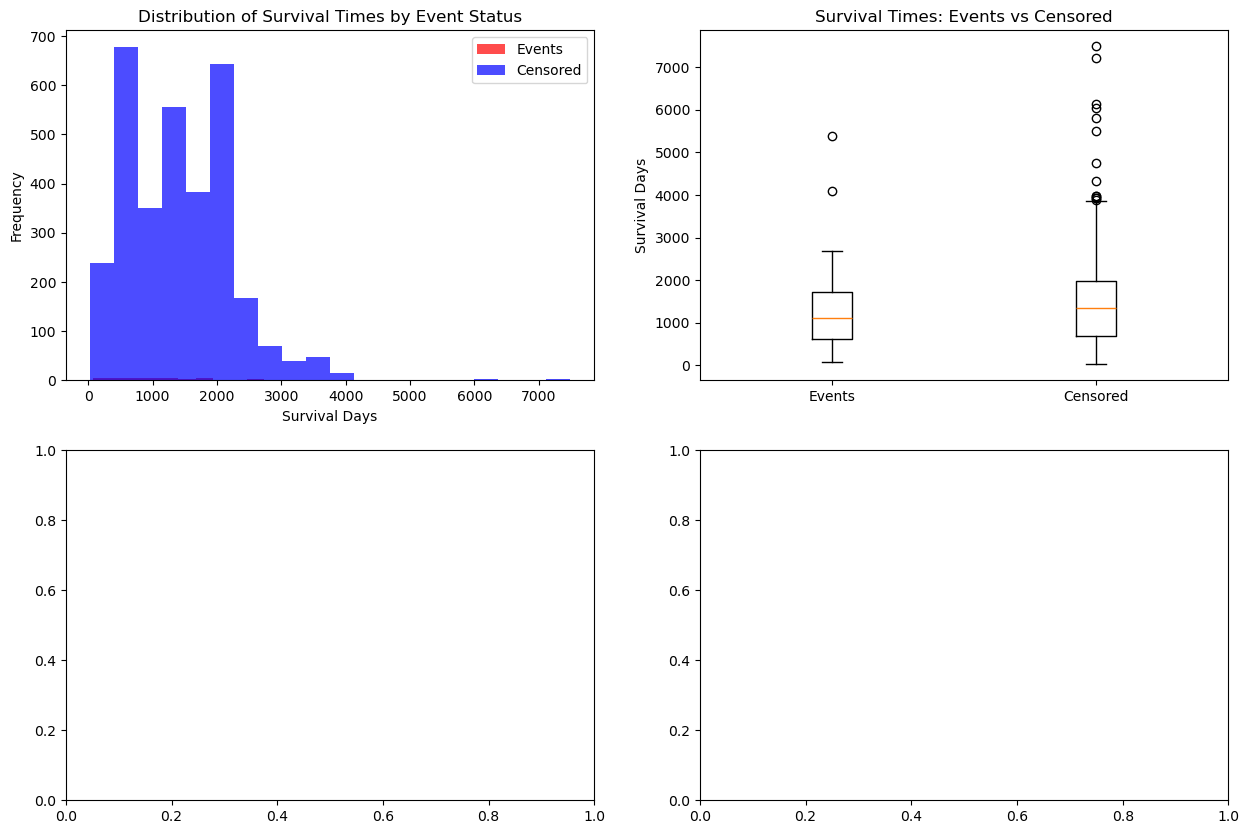

In [6]:
# Analyze censoring patterns over time
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 2, figsize=(15, 10))

# 1. Histogram of survival times by event status
axes[0, 0].hist(survival_dataset[survival_dataset['Regional LN recurrence'] == 1]['Survival days'], 
                alpha=0.7, label='Events', bins=20, color='red')
axes[0, 0].hist(survival_dataset[survival_dataset['Regional LN recurrence'] == 0]['Survival days'], 
                alpha=0.7, label='Censored', bins=20, color='blue')
axes[0, 0].set_xlabel('Survival Days')
axes[0, 0].set_ylabel('Frequency')
axes[0, 0].set_title('Distribution of Survival Times by Event Status')
axes[0, 0].legend()

# 2. Box plot comparing survival times
event_data = survival_dataset[survival_dataset['Regional LN recurrence'] == 1]['Survival days']
censored_data = survival_dataset[survival_dataset['Regional LN recurrence'] == 0]['Survival days']
axes[0, 1].boxplot([event_data, censored_data], labels=['Events', 'Censored'])
axes[0, 1].set_ylabel('Survival Days')
axes[0, 1].set_title('Survival Times: Events vs Censored')

# 3. Cumulative distribution of survival times
sorted_event_times = np.sort(event_data) if len(event_data) > 0 else []
sorted_censored_times = np.sort(censored_data) if len(censored_data) > 0 else []

if len(sorted_event_times) > 0:
    axes[1, 0].plot(sorted_event_times, np.arange(1, len(sorted_event_times) + 1) / len(sorted_event_times), 
                    label='Events', color='red', linewidth=2)
if len(sorted_censored_times) > 0:
    axes[1, 0].plot(sorted_censored_times, np.arange(1, len(sorted_censored_times) + 1) / len(sorted_censored_times), 
                    label='Censored', color='blue', linewidth=2)
axes[1, 0].set_xlabel('Survival Days')
axes[1, 0].set_ylabel('Cumulative Proportion')
axes[1, 0].set_title('Cumulative Distribution of Survival Times')
axes[1, 0].legend()

# 4. Time to event vs censoring pattern
all_times = survival_dataset['Survival days'].values
all_events = survival_dataset['Regional LN recurrence'].values
time_bins = np.linspace(0, max(all_times), 10)
bin_centers = (time_bins[:-1] + time_bins[1:]) / 2

event_rates = []
for i in range(len(time_bins) - 1):
    mask = (all_times >= time_bins[i]) & (all_times < time_bins[i + 1])
    if np.sum(mask) > 0:
        event_rate = np.mean(all_events[mask])
    else:
        event_rate = 0
    event_rates.append(event_rate)

axes[1, 1].bar(bin_centers, event_rates, width=(time_bins[1] - time_bins[0]) * 0.8, alpha=0.7)
axes[1, 1].set_xlabel('Survival Days (Binned)')
axes[1, 1].set_ylabel('Event Rate')
axes[1, 1].set_title('Event Rate Across Time Periods')
axes[1, 1].set_ylim(0, 1)

plt.tight_layout()
plt.show()

In [ ]:
# Advanced censoring analysis
print("=== CENSORING PATTERN ANALYSIS ===")

# Check if censoring is informative (related to survival time)
if len(event_times) > 0 and len(censored_times) > 0:
    from scipy.stats import mannwhitneyu
    
    # Mann-Whitney U test to compare survival times between groups
    statistic, p_value = mannwhitneyu(event_times, censored_times, alternative='two-sided')
    print(f"Mann-Whitney U test (event times vs censored times):")
    print(f"  Statistic: {statistic:.3f}")
    print(f"  P-value: {p_value:.4f}")
    
    if p_value < 0.05:
        print("  ⚠️  Significant difference in survival times between groups")
        print("     This could indicate informative censoring")
    else:
        print("  ✅ No significant difference in survival times")
        print("     Suggests non-informative (random) censoring")
    
    print()

# Calculate censoring distribution over time quartiles
print("Censoring rate by survival time quartiles:")
quartiles = np.percentile(survival_dataset['Survival days'], [25, 50, 75])

q1_mask = survival_dataset['Survival days'] <= quartiles[0]
q2_mask = (survival_dataset['Survival days'] > quartiles[0]) & (survival_dataset['Survival days'] <= quartiles[1])
q3_mask = (survival_dataset['Survival days'] > quartiles[1]) & (survival_dataset['Survival days'] <= quartiles[2])
q4_mask = survival_dataset['Survival days'] > quartiles[2]

for i, (mask, label) in enumerate([(q1_mask, 'Q1 (0-25%)'), (q2_mask, 'Q2 (25-50%)'), 
                                   (q3_mask, 'Q3 (50-75%)'), (q4_mask, 'Q4 (75-100%)')]):
    q_data = survival_dataset[mask]
    if len(q_data) > 0:
        censoring_rate = (q_data['Regional LN recurrence'] == 0).mean()
        print(f"  {label}: {censoring_rate:.3f} ({censoring_rate*100:.1f}% censored, n={len(q_data)})")

print()

# Administrative vs natural censoring analysis
max_follow_up = survival_dataset['Survival days'].max()
median_follow_up = survival_dataset['Survival days'].median()

# Count patients censored at or near maximum follow-up (administrative censoring)
admin_censored = ((survival_dataset['Regional LN recurrence'] == 0) & 
                  (survival_dataset['Survival days'] >= max_follow_up * 0.95)).sum()

print(f"Patients likely administratively censored (≥95% of max follow-up): {admin_censored}")
print(f"Administrative censoring rate: {admin_censored/total_patients:.3f} ({admin_censored/total_patients*100:.1f}%)")

# Early censoring (potentially problematic)
early_censored = ((survival_dataset['Regional LN recurrence'] == 0) & 
                  (survival_dataset['Survival days'] <= median_follow_up * 0.25)).sum()
print(f"Patients with early censoring (≤25% of median follow-up): {early_censored}")
print(f"Early censoring rate: {early_censored/total_patients:.3f} ({early_censored/total_patients*100:.1f}%)")

=== CENSORING PATTERN ANALYSIS ===
Mann-Whitney U test (event times vs censored times):
  Statistic: 48944.000
  P-value: 0.1245
  ✅ No significant difference in survival times
     Suggests non-informative (random) censoring

Censoring rate by survival time quartiles:
  Q1 (0-25%): 0.988 (98.8% censored, n=808)
  Q2 (25-50%): 0.985 (98.5% censored, n=807)
  Q3 (50-75%): 0.989 (98.9% censored, n=808)
  Q4 (75-100%): 0.994 (99.4% censored, n=807)

Patients likely administratively censored (≥95% of max follow-up): 2
Administrative censoring rate: 0.001 (0.1%)
Patients with early censoring (≤25% of median follow-up): 138
Early censoring rate: 0.043 (4.3%)


## Reading these numbers

Class imbalance is just more observations in one class than another (more censored than events, in our case). Heavy censoring is different: a high fraction censored (>70-80% is the usual cutoff) causes real problems, less statistical power, harder model convergence, shaky parameter estimates, worse predictive performance.

Things that point to *problematic* heavy censoring specifically: censoring rate above 80%, censored/event survival times that differ significantly (informative censoring), lots of patients censored early in follow-up, or censoring that is uneven across time periods.

So: >80% censored means heavy censoring. Mann-Whitney p<0.05 means censoring might be informative. High early-censoring rate could mean a data quality issue. Uneven censoring across quartiles could mean systematic bias.

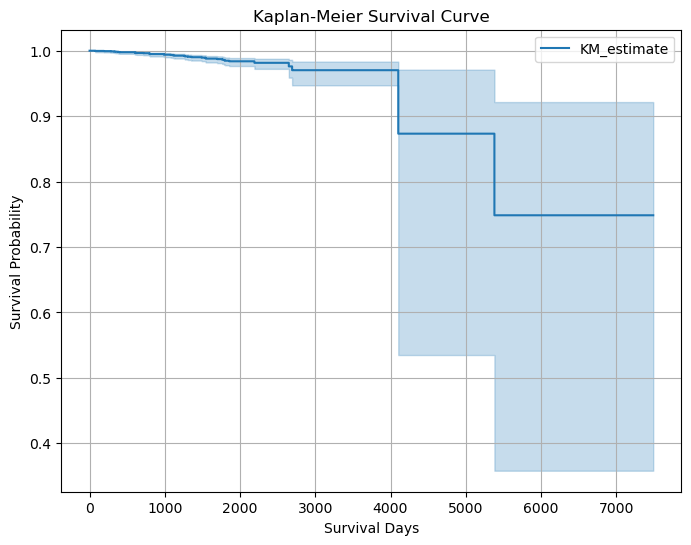

In [ ]:
# Kaplan-Meier survival curve
from lifelines import KaplanMeierFitter
import matplotlib.pyplot as plt

kmf = KaplanMeierFitter()
T = survival_dataset['Survival days']
E = survival_dataset['Regional LN recurrence']

plt.figure(figsize=(8, 6))
kmf.fit(T, event_observed=E)
kmf.plot_survival_function(ci_show=True)
plt.title('Kaplan-Meier Survival Curve')
plt.xlabel('Survival Days')
plt.ylabel('Survival Probability')
plt.grid(True)
plt.show()